In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)


In [ ]:
df = pd.read_csv("/content/spam.csv", encoding="latin-1")
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
df.shape

(5572, 5)

In [ ]:
df.isnull().sum()

,0
v1,0
v2,0
Unnamed: 2,5522
Unnamed: 3,5560
Unnamed: 4,5566


In [ ]:
df = df[['v1', 'v2']]
df.columns = ['label', 'text']


In [ ]:
df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
df.isnull().sum()

,0
label,0
text,0


In [ ]:
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

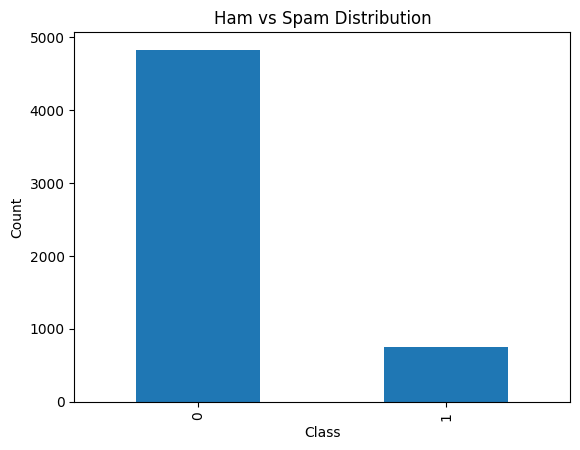

In [ ]:
df['label'].value_counts().plot(kind='bar')
plt.title('Ham vs Spam Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

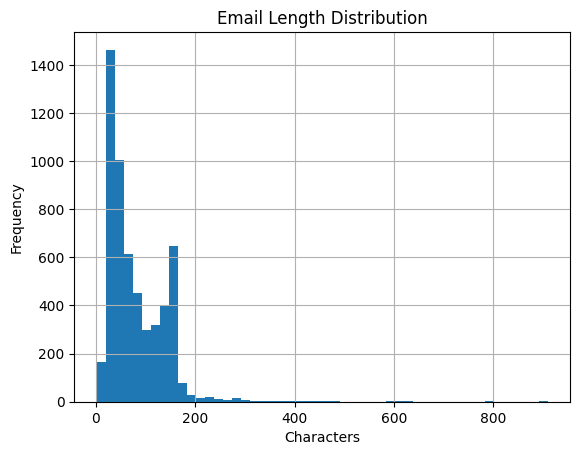

In [ ]:
df['text'].apply(len).hist(bins=50)
plt.title("Email Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")
plt.show()

TF-IDF converts text into numerical features by giving high weight to words that are frequent in a document but rare across the dataset, making it effective for text classification.



In [ ]:
vectorizer = TfidfVectorizer(
    stop_words='english',
    max_df=0.9,
    min_df=5
)

X = vectorizer.fit_transform(df['text'])
y = df['label']


In [ ]:
print(X)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 32990 stored elements and shape (5572, 1602)>
  Coords	Values
  (0, 1059)	0.3427615938187783
  (0, 359)	0.33937682868048286
  (0, 163)	0.32777968135451047
  (0, 237)	0.37021614048454177
  (0, 600)	0.24207696703883225
  (0, 1558)	0.29642665139407415
  (0, 757)	0.37021614048454177
  (0, 301)	0.37021614048454177
  (0, 596)	0.2056563631231204
  (0, 1504)	0.24485466934992717
  (1, 980)	0.3249570176155611
  (1, 764)	0.4875783329044985
  (1, 732)	0.6253222261474617
  (1, 1529)	0.5154051022937713
  (2, 543)	0.16298334746143545
  (2, 476)	0.5086618221958081
  (2, 1543)	0.2692371146593385
  (2, 325)	0.27480665371020807
  (2, 1533)	0.20928241003986844
  (2, 366)	0.2891186414719509
  (2, 521)	0.26003677385686214
  (2, 1360)	0.17362002760180664
  (2, 1121)	0.23625996091876136
  (2, 1094)	0.2526008316572831
  (2, 1302)	0.2779219462185074
  :	:
  (5567, 937)	0.2781288146228813
  (5567, 47)	0.26533728731750844
  (5567, 1419)	0.2781288146228

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


Linear SVM is preferred for text classification because TF-IDF creates high-dimensional sparse data that is efficiently and accurately separated using a linear decision boundary.



In [ ]:
model = LinearSVC()
model.fit(X_train, y_train)

LinearSVC()

In [ ]:
y_pred = model.predict(X_test)


In [ ]:
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.9820627802690582
Precision: 0.9849624060150376
Recall   : 0.8791946308724832
F1 Score : 0.9290780141843972


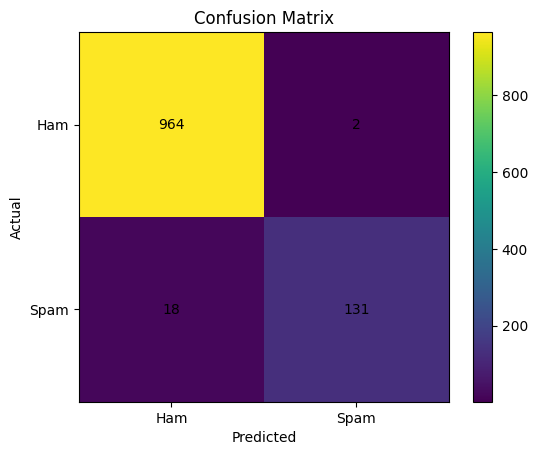

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0,1], ['Ham','Spam'])
plt.yticks([0,1], ['Ham','Spam'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()


F1-Score is the best primary metric for this use case

Why?

Spam detection is imbalanced

Both false positives and false negatives matter

F1 balances both risks